Ligação à base de dados estabelecida com sucesso para a camada Gold!


,nome_orgao_superior,custo_total,custo_milhoes
0,Ministério da Justiça e Segurança Pública,4.869331e+08,486.933122
1,Ministério da Defesa,1.560703e+08,156.070304
2,Ministério da Educação,1.112913e+08,111.291349
3,Ministério do Meio Ambiente e Mudança do Clima,4.969771e+07,49.697710
4,Ministério da Previdência Social,4.041731e+07,40.417309


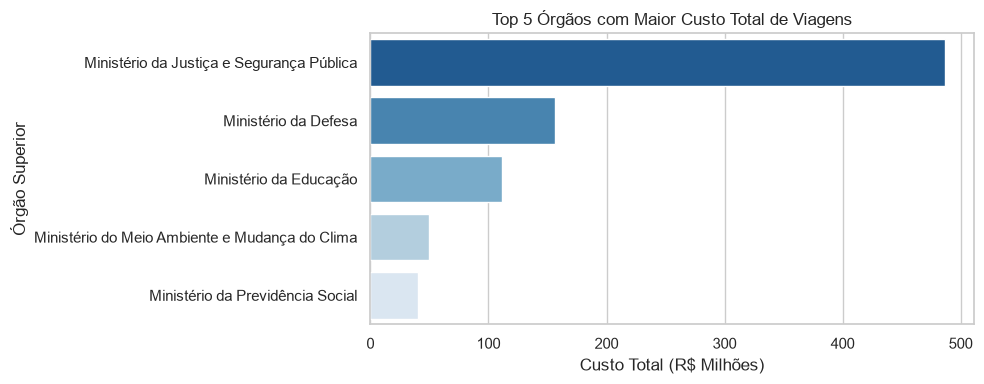

In [8]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from banco import conectar

# Ignora avisos desnecessários do pandas/database no output
warnings.filterwarnings('ignore', category=UserWarning)

# Estilo visual limpo para os gráficos
sns.set_theme(style='whitegrid')

conexao = conectar()
print(
    'Ligação à base de dados estabelecida com sucesso para a camada Gold!'
)

query_top_orgaos = """
    SELECT nome_orgao_superior, SUM(valor_total) AS custo_total
    FROM silver_viagem
    GROUP BY nome_orgao_superior
    ORDER BY custo_total DESC
    LIMIT 5;
"""

df_orgaos = pd.read_sql(query_top_orgaos, conexao)

# Converte para milhões para a leitura dos números ficar limpa no gráfico
df_orgaos['custo_milhoes'] = df_orgaos['custo_total'] / 1e6
display(df_orgaos)

# Gráfico ajustado sem avisos de depreciação do Seaborn
plt.figure(figsize=(10, 4))
sns.barplot(
    data=df_orgaos,
    x='custo_milhoes',
    y='nome_orgao_superior',
    hue='nome_orgao_superior',
    palette='Blues_r',
    legend=False,
)
plt.title('Top 5 Órgãos com Maior Custo Total de Viagens')
plt.xlabel('Custo Total (R$ Milhões)')
plt.ylabel('Órgão Superior')
plt.tight_layout()
plt.show()

In [9]:
cursor = conexao.cursor()

cursor.execute("""
    CREATE OR REPLACE VIEW gold_resumo_orgaos AS
    SELECT 
        nome_orgao_superior,
        COUNT(id_viagem) as total_viagens,
        SUM(valor_total) as custo_total,
        AVG(valor_total) as custo_medio,
        AVG(duracao_dias) as duracao_media_dias
    FROM silver_viagem
    GROUP BY nome_orgao_superior;
""")
conexao.commit()
cursor.close()

print("View 'gold_resumo_orgaos' criada com sucesso no PostgreSQL!")

View 'gold_resumo_orgaos' criada com sucesso no PostgreSQL!


--- 1. Destinos com maior custo médio por viagem ---


,destinos,custo_medio,total_viagens
0,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita,...",245852.80,1
1,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC...",216729.36,1
2,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis...",207220.14,1


--- 2. Meio de transporte mais usado nos trechos ---


,meio_transporte,total_utilizacoes
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


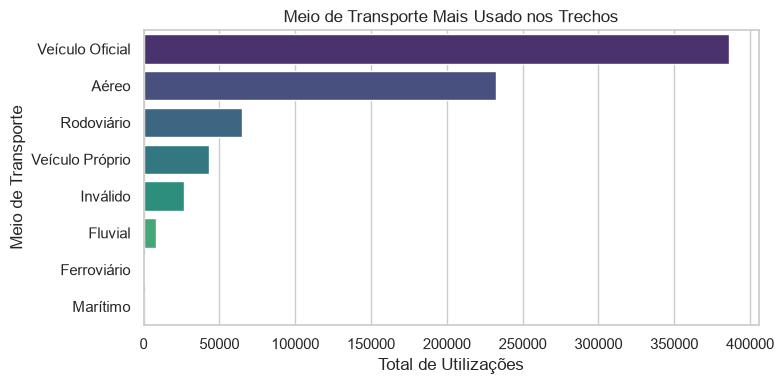

--- 3. Tipo de pagamento com maior valor médio ---


,tipo_pagamento,valor_medio,quantidade
0,DIÁRIAS,2078.280299,401463
1,PASSAGEM,1878.344393,188985
2,Serviço correlato: seguro,447.514653,4894
3,RESTITUIÇÃO,245.702610,11574


In [10]:
# ==========================================
# Pergunta: Os 3 destinos com maior custo médio por viagem
# ==========================================
print('--- 1. Destinos com maior custo médio por viagem ---')
query_destinos = """
    SELECT destinos, AVG(valor_total) AS custo_medio, COUNT(id_viagem) AS total_viagens
    FROM silver_viagem
    WHERE destinos IS NOT NULL AND destinos != ''
    GROUP BY destinos
    ORDER BY custo_medio DESC
    LIMIT 3;
"""
df_destinos = pd.read_sql(query_destinos, conexao)
display(df_destinos)

# ==========================================
# Pergunta: Qual o meio de transporte mais usado nos trechos?
# ==========================================
print('--- 2. Meio de transporte mais usado nos trechos ---')
query_transporte = """
    SELECT meio_transporte, COUNT(*) AS total_utilizacoes
    FROM silver_trecho
    WHERE meio_transporte IS NOT NULL AND meio_transporte != ''
    GROUP BY meio_transporte
    ORDER BY total_utilizacoes DESC;
"""
df_transporte = pd.read_sql(query_transporte, conexao)
display(df_transporte)

plt.figure(figsize=(8, 4))
sns.barplot(
    data=df_transporte,
    x='total_utilizacoes',
    y='meio_transporte',
    hue='meio_transporte',
    palette='viridis',
    legend=False,
)
plt.title('Meio de Transporte Mais Usado nos Trechos')
plt.xlabel('Total de Utilizações')
plt.ylabel('Meio de Transporte')
plt.tight_layout()
plt.show()

# ==========================================
# Pergunta: Qual o tipo de pagamento com maior valor médio?
# ==========================================
print('--- 3. Tipo de pagamento com maior valor médio ---')
query_pagamento = """
    SELECT tipo_pagamento, AVG(valor) AS valor_medio, COUNT(*) AS quantidade
    FROM silver_pagamento
    GROUP BY tipo_pagamento
    ORDER BY valor_medio DESC;
"""
df_pagamento = pd.read_sql(query_pagamento, conexao)
display(df_pagamento)

--- 4. Viagem de maior duração e o seu custo total ---


,id_viagem,nome_viajante,nome_orgao_superior,duracao_dias,valor_total
0,0000000000020699856,LUISANGELA CORREA FRANCO DE FARIA,Ministério da Previdência Social,384,0.0


--- 5. UF de destino que aparece em mais trechos ---


,destino_uf,total_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603


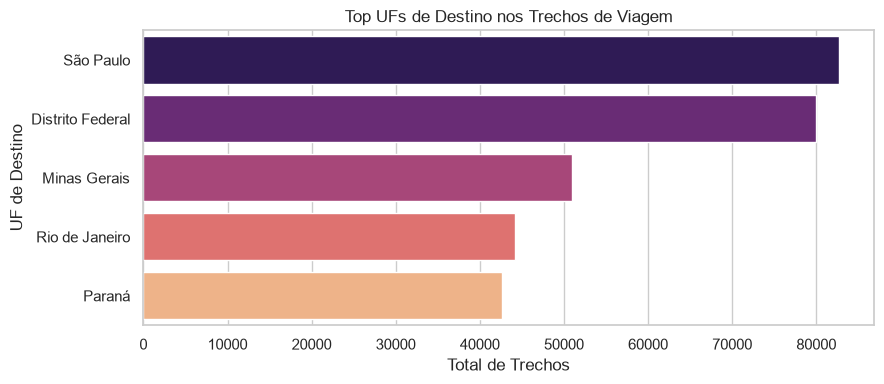

In [11]:
# ==========================================
# Pergunta: A viagem de maior duração e o seu custo total
# ==========================================
print('--- 4. Viagem de maior duração e o seu custo total ---')
query_maior_viagem = """
    SELECT id_viagem, nome_viajante, nome_orgao_superior, duracao_dias, valor_total
    FROM silver_viagem
    ORDER BY duracao_dias DESC
    LIMIT 1;
"""
df_maior_viagem = pd.read_sql(query_maior_viagem, conexao)
display(df_maior_viagem)

# ==========================================
# Pergunta: Qual a UF de destino que aparece em mais trechos?
# ==========================================
print('--- 5. UF de destino que aparece em mais trechos ---')
query_uf_destino = """
    SELECT destino_uf, COUNT(*) AS total_trechos
    FROM silver_trecho
    WHERE destino_uf IS NOT NULL AND destino_uf != ''
    GROUP BY destino_uf
    ORDER BY total_trechos DESC
    LIMIT 5;
"""
df_uf_destino = pd.read_sql(query_uf_destino, conexao)
display(df_uf_destino)

plt.figure(figsize=(9, 4))
sns.barplot(
    data=df_uf_destino,
    x='total_trechos',
    y='destino_uf',
    hue='destino_uf',
    palette='magma',
    legend=False,
)
plt.title('Top UFs de Destino nos Trechos de Viagem')
plt.xlabel('Total de Trechos')
plt.ylabel('UF de Destino')
plt.tight_layout()
plt.show()
